Accuracy: 94.73684210526315 %


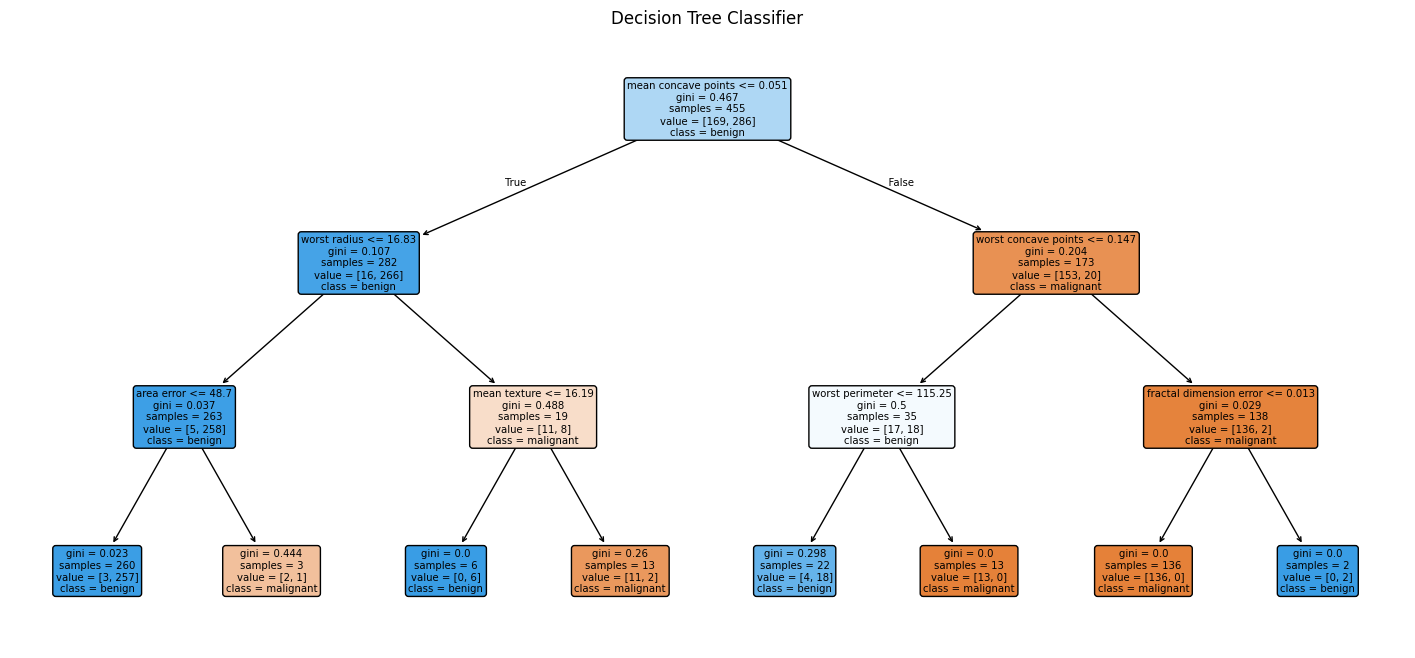

In [3]:
# EXPE-6

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Decision Tree
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

# Evaluate model
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

# Display Decision Tree
plt.figure(figsize=(18, 8))
plot_tree(
    model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Classifier")
plt.show()


Accuracy: 0.8146
F1-Score: 0.8362


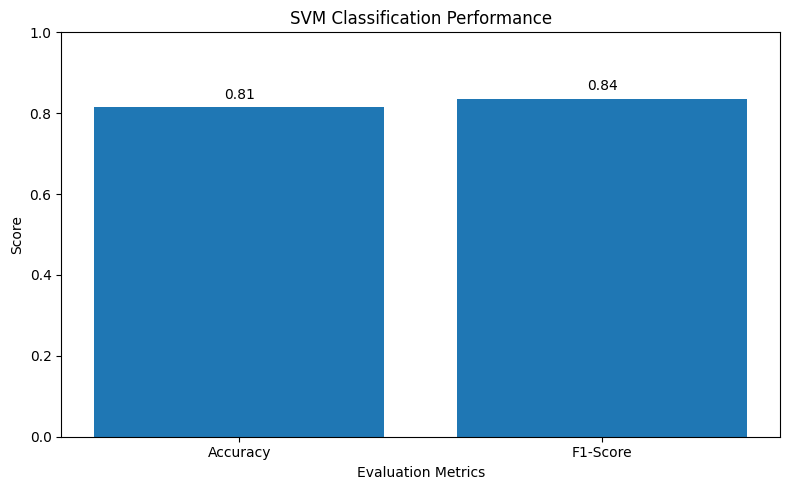

In [7]:
# EXP-7
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# Load Dataset
data = pd.read_csv("heart.csv")

# Separate Input and Output
X = data.drop("target", axis=1)
y = data["target"]

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train SVM Model
model = SVC(kernel="linear")
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Calculate Accuracy and F1-Score
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, zero_division=0)
print("Accuracy:", round(accuracy, 4))
print("F1-Score:", round(f1, 4))

#  Draw Graph
metrics = ["Accuracy", "F1-Score"]
scores = [accuracy, f1]
plt.figure(figsize=(8, 5))
plt.bar(metrics, scores)
plt.ylim(0, 1)
plt.title("SVM Classification Performance")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
for i, score in enumerate(scores):
    plt.text(i, score + 0.02, f"{score:.2f}", ha="center")

plt.tight_layout()
plt.show()

C:\Users\dines\AppData\Roaming\Python\Python313\site-packages\sklearn\cluster\_kmeans.py:1425: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Customer Clusters:
   Annual Income (k$)  Spending Score (1-100)  Cluster
0                  15                      39        4
1                  15                      81        2
2                  16                       6        4
3                  16                      77        2
4                  17                      40        4

Number of Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


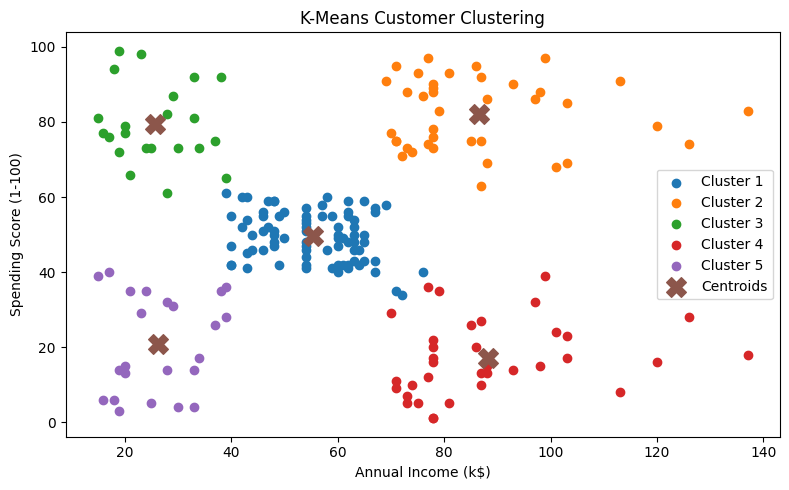

In [1]:
# EXP-8
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Load Dataset
data = pd.read_csv("Mall_Customers.csv")

# Select Features
X = data[["Annual Income (k$)", "Spending Score (1-100)"]]

# Apply K-Means
model = KMeans(n_clusters=5, random_state=42, n_init=10)
data["Cluster"] = model.fit_predict(X)

# Display Cluster Information
print("Customer Clusters:")
print(data[["Annual Income (k$)", "Spending Score (1-100)", "Cluster"]].head())

print("\nNumber of Customers in Each Cluster:")
print(data["Cluster"].value_counts().sort_index())

# Visualize Clusters
plt.figure(figsize=(8, 5))

for i in range(5):
    cluster = data[data["Cluster"] == i]
    plt.scatter(
        cluster["Annual Income (k$)"],
        cluster["Spending Score (1-100)"],
        label=f"Cluster {i+1}"
    )

# Display Cluster Centers
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    s=200,
    marker="X",
    label="Centroids"
)

plt.title("K-Means Customer Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()
plt.show()

Original Features: 13
Reduced Features: 2
Variance Explained: 55.41 %


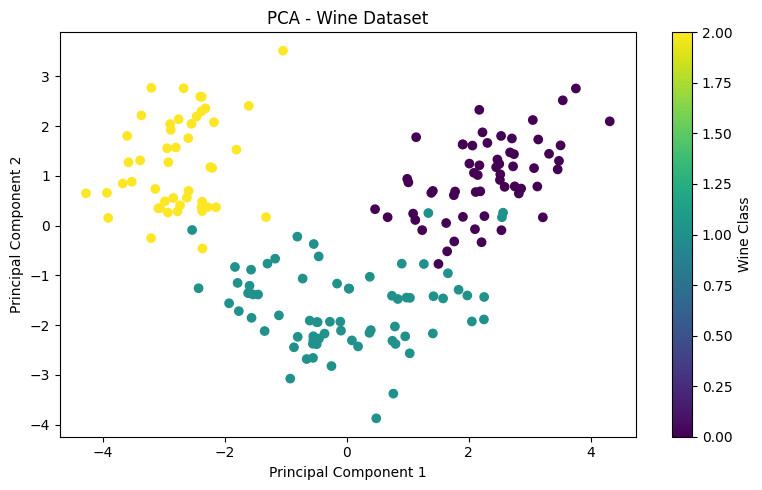

In [4]:
# EXP-9
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load Dataset
data = load_wine()
X = data.data

# Standardize Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Display Results
print("Original Features:", X.shape[1])
print("Reduced Features:", X_pca.shape[1])

print("Variance Explained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# Visualize Results
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data.target,
    cmap="viridis"
)

plt.title("PCA - Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Wine Class")
plt.tight_layout()
plt.show()

In [1]:
# EXPERIMENT-5
# Import libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

# Load dataset
df = pd.read_csv("Iris.csv")

# Remove ID column
df = df.drop("Id", axis=1, errors="ignore")

# Separate input and output
X = df.drop("Species", axis=1)
y = df["Species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
) 
# Scale the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create and train KNN model
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Predict results
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Calculate F1 score
f1 = f1_score(y_test, y_pred, average="weighted")
print("F1 Score:", round(f1, 4))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

#  Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 100.0 %
F1 Score: 1.0

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



First 5 Records:
   Unnamed: 0  YearsExperience   Salary
0           0              1.2  39344.0
1           1              1.4  46206.0
2           2              1.6  37732.0
3           3              2.1  43526.0
4           4              2.3  39892.0

Actual Salaries:
[112636.  67939. 113813.  83089.  64446.  57190.]

Predicted Salaries:
[115791.21011287  71499.27809463 102597.86866063  75268.80422384
  55478.79204548  60190.69970699]

Model Evaluation:
Mean Squared Error: 49830096.855908334
R2 Score: 0.9024461774180498

Linear Regression Equation:
Salary = 9423.81532303098 * YearsExperience + 24380.20147947369


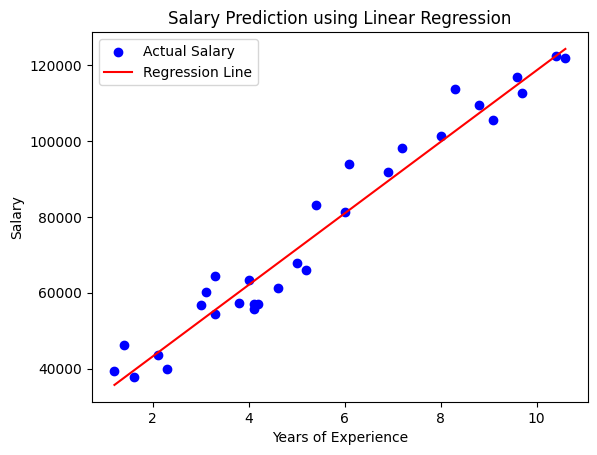


Years of Experience: 5
Predicted Salary: 71499.28


In [3]:
# EXPE-4
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("Salary_dataset.csv")

print("First 5 Records:")
print(df.head())

# Select input and output
X = df[["YearsExperience"]]
y = df["Salary"]

#  Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#  Create and train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict salary
y_pred = model.predict(X_test)

print("\nActual Salaries:")
print(y_test.to_numpy())

print("\nPredicted Salaries:")
print(y_pred)

# Evaluate model
print("\nModel Evaluation:")
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

# Display equation
print("\nLinear Regression Equation:")
print("Salary =", model.coef_[0], "* YearsExperience +", model.intercept_)

# Plot graph
plt.scatter(X, y, color="blue", label="Actual Salary")
plt.plot(X, model.predict(X), color="red", label="Regression Line")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Salary Prediction using Linear Regression")
plt.legend()
plt.show()

# Predict salary for new experience
years = pd.DataFrame({"YearsExperience": [5]})
predicted_salary = model.predict(years)

print("\nYears of Experience:", 5)
print("Predicted Salary:", round(predicted_salary[0], 2))

In [4]:
import numpy as np

print(np.__version__)

2.3.5


In [5]:
a = np.array([10, 20, 30, 40, 50])

print(a)

[10 20 30 40 50]


In [6]:
print(type(a))
print(a.ndim)
print(a.shape)
print(a.size)
print(a.dtype)

<class 'numpy.ndarray'>
1
(5,)
5
int64


In [7]:
a = np.zeros(5)
print(a)

a = np.zeros((3, 4))
print(a)

a = np.arange(1, 11)
print(a)

a = np.arange(2, 11, 2)
print(a)

[0. 0. 0. 0. 0.]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
[ 1  2  3  4  5  6  7  8  9 10]
[ 2  4  6  8 10]


In [8]:
a = np.arange(1, 13)
print(a)

b = a.reshape(3, 4)
print(b)

[ 1  2  3  4  5  6  7  8  9 10 11 12]
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]


In [9]:
a = np.array([10, 20, 30, 40, 50])

print(a[0])
print(a[2])
print(a[4])

10
30
50


In [10]:
a = np.array([10, 20, 30])
b = np.array([1, 2, 3])

print(a + b)

a = np.array([10, 20, 30, 40, 50])

print(np.sum(a))
print(np.mean(a))
print(np.median(a))
print(np.min(a))
print(np.max(a))
print(np.std(a))
print(np.var(a))

[11 22 33]
150
30.0
30.0
10
50
14.142135623730951
200.0


In [10]:
a = np.array([10, 20, 30])
b = np.array([1, 2, 3])

print(a + b)

a = np.array([10, 20, 30, 40, 50])

print(np.sum(a))
print(np.mean(a))
print(np.median(a))
print(np.min(a))
print(np.max(a))
print(np.std(a))
print(np.var(a))

[11 22 33]
150
30.0
30.0
10
50
14.142135623730951
200.0


In [13]:
import pandas as pd

print(pd.__version__)

2.3.3


In [14]:
marks = pd.Series([65, 78, 82, 55, 90])

print(marks)

0    65
1    78
2    82
3    55
4    90
dtype: int64


In [15]:
marks = pd.Series(
    [65, 78, 82],
    index=["Student1", "Student2", "Student3"]
)

print(marks)

print(marks["Student2"])

Student1    65
Student2    78
Student3    82
dtype: int64
78


In [16]:
data = {
    "Study_Hours": [2, 4, 5, 7, 8],
    "Attendance": [60, 70, 75, 85, 90],
    "Marks": [50, 60, 65, 78, 88]
}

df = pd.DataFrame(data)

print(df)

   Study_Hours  Attendance  Marks
0            2          60     50
1            4          70     60
2            5          75     65
3            7          85     78
4            8          90     88


In [17]:
print(df.head())

print(df.head(3))

print(df.tail())

print(df.shape)

print(df.columns)

print(df.dtypes)

df.info()

   Study_Hours  Attendance  Marks
0            2          60     50
1            4          70     60
2            5          75     65
3            7          85     78
4            8          90     88
   Study_Hours  Attendance  Marks
0            2          60     50
1            4          70     60
2            5          75     65
   Study_Hours  Attendance  Marks
0            2          60     50
1            4          70     60
2            5          75     65
3            7          85     78
4            8          90     88
(5, 3)
Index(['Study_Hours', 'Attendance', 'Marks'], dtype='object')
Study_Hours    int64
Attendance     int64
Marks          int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  5 non-null      int64
 1   Attendance   5 non-null      int64
 2   Marks        5 non-null      int64
dtypes: in

In [18]:
import matplotlib.pyplot as plt
import matplotlib

print(matplotlib.__version__)

3.10.8


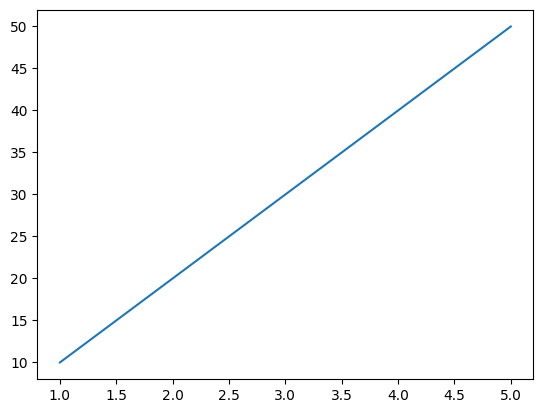

In [19]:
x = [1, 2, 3, 4, 5]
y = [10, 20, 30, 40, 50]

plt.plot(x, y)

plt.show()

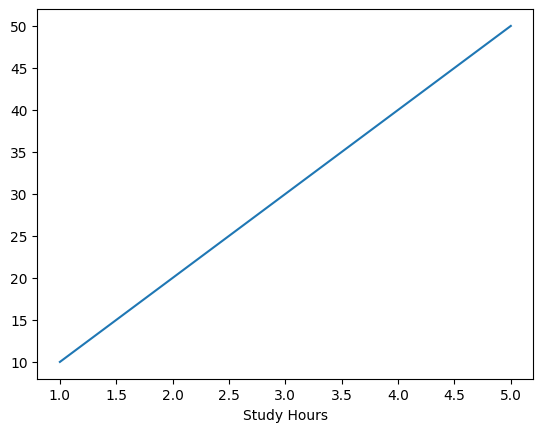

In [20]:
plt.plot(x, y)

plt.xlabel("Study Hours")

plt.show()

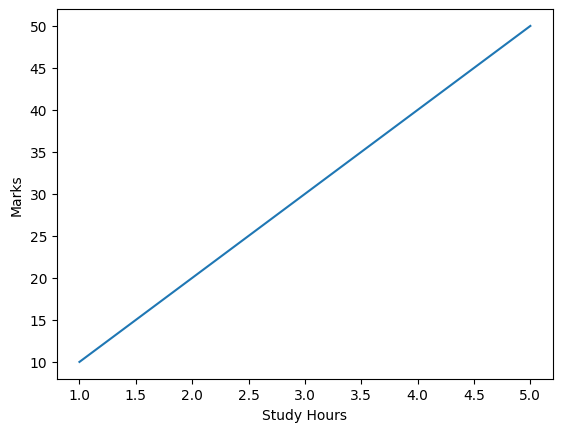

In [22]:
plt.plot(x, y)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.show()

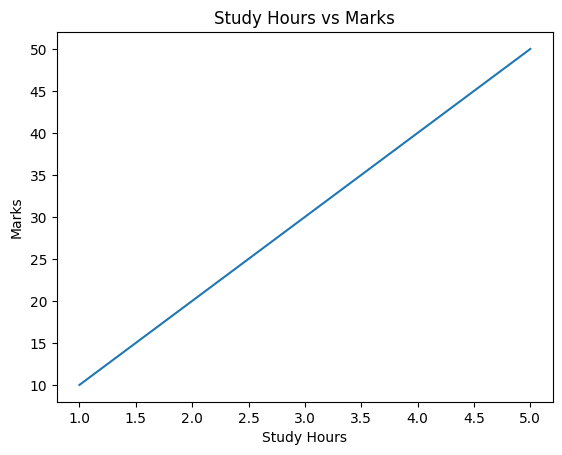

In [23]:
plt.plot(x, y)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")
plt.show()

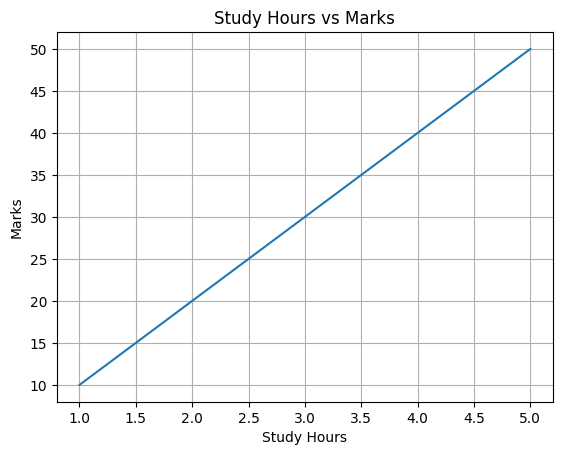

In [24]:
plt.plot(x, y)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")
plt.grid()
plt.show()

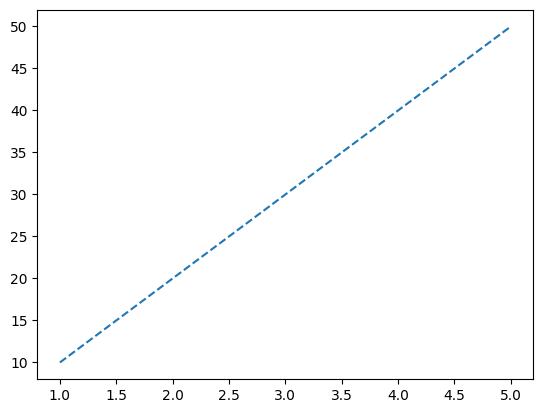

In [25]:
plt.plot(x, y, linestyle="--")
plt.show()

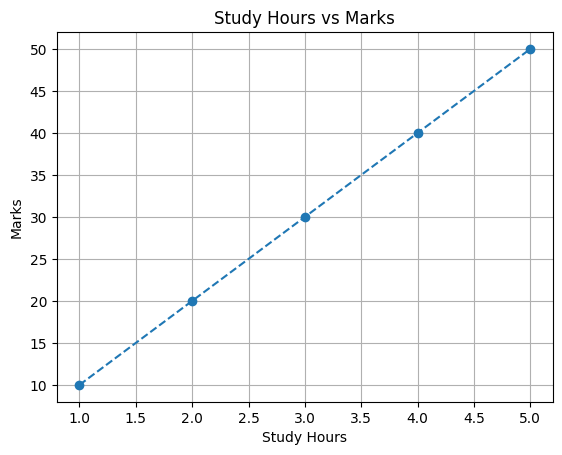

In [26]:
plt.plot(x, y, marker="o", linestyle="--")
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")
plt.grid()
plt.show()

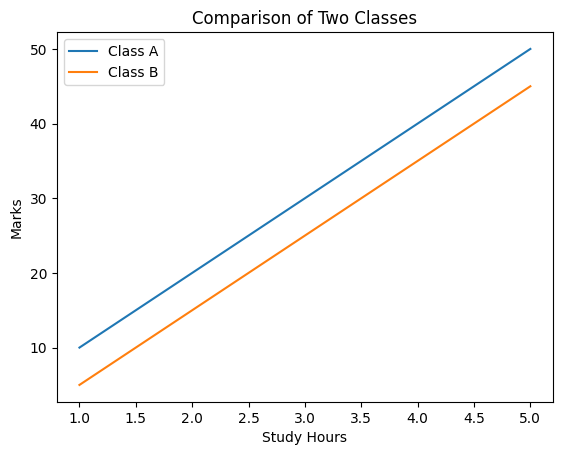

In [27]:
x = [1, 2, 3, 4, 5]
y1 = [10, 20, 30, 40, 50]
y2 = [5, 15, 25, 35, 45]

plt.plot(x, y1, label="Class A")
plt.plot(x, y2, label="Class B")

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Comparison of Two Classes")
plt.legend()
plt.show()

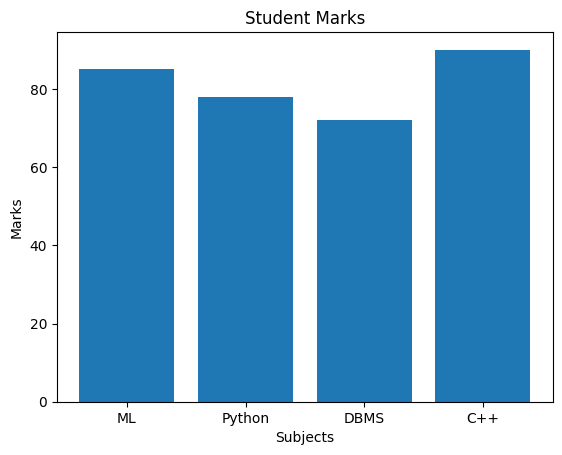

In [28]:
subjects = ["ML", "Python", "DBMS", "C++"]
marks = [85, 78, 72, 90]

plt.bar(subjects, marks)
plt.xlabel("Subjects")
plt.ylabel("Marks")
plt.title("Student Marks")
plt.show()

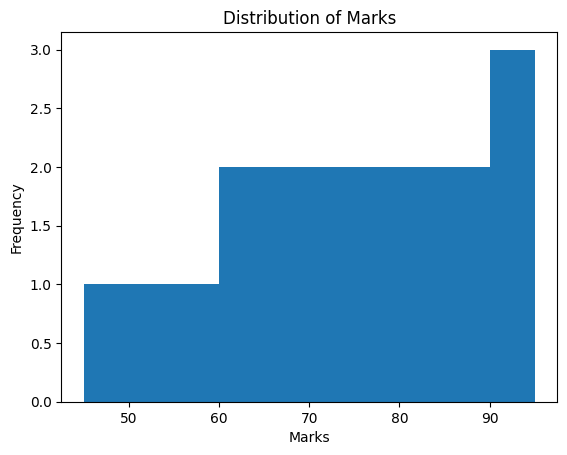

In [29]:
marks = [
    45, 50, 55, 60, 62, 65, 68, 70, 72,
    75, 78, 80, 82, 85, 88, 90, 92, 95
]

plt.hist(marks)
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.title("Distribution of Marks")
plt.show()

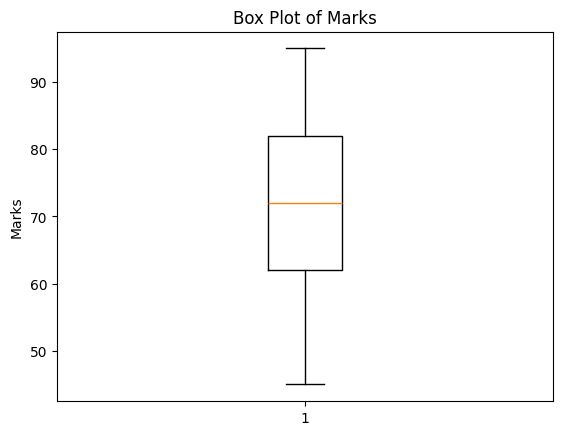

In [30]:
marks = [
    45, 50, 55, 60, 62, 65, 68, 70,
    72, 75, 78, 80, 82, 85, 88, 90, 95
]

plt.boxplot(marks)
plt.ylabel("Marks")
plt.title("Box Plot of Marks")
plt.show()

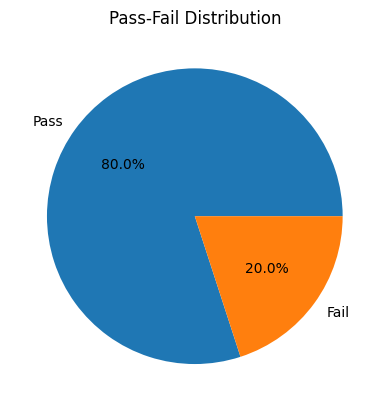

In [31]:
labels = ["Pass", "Fail"]
values = [80, 20]

plt.pie(values, labels=labels, autopct="%1.1f%%")
plt.title("Pass-Fail Distribution")
plt.show()

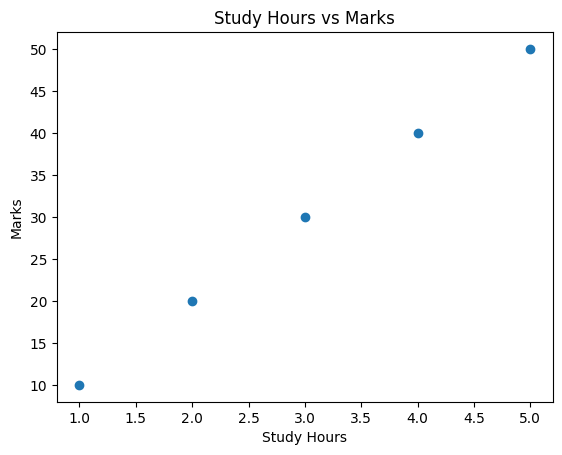

In [32]:
x = [1, 2, 3, 4, 5]
y = [10, 20, 30, 40, 50]

plt.scatter(x, y)
plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Study Hours vs Marks")
plt.show()

In [34]:
import seaborn as sns
print(sns.__version__)

0.13.2


In [35]:
import pandas as pd

data = {
    "Study_Hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Attendance": [55, 60, 65, 68, 72, 75, 80, 85, 88, 92],
    "Marks": [35, 42, 48, 55, 60, 68, 72, 78, 85, 92]
}

df = pd.DataFrame(data)
print(df)

   Study_Hours  Attendance  Marks
0            1          55     35
1            2          60     42
2            3          65     48
3            4          68     55
4            5          72     60
5            6          75     68
6            7          80     72
7            8          85     78
8            9          88     85
9           10          92     92


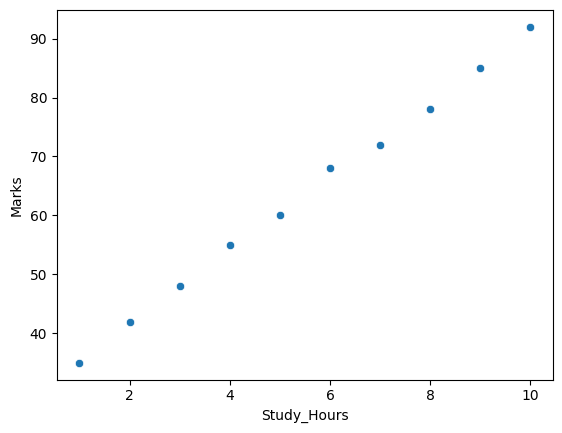

In [36]:
sns.scatterplot(data=df, x="Study_Hours", y="Marks")
plt.show()

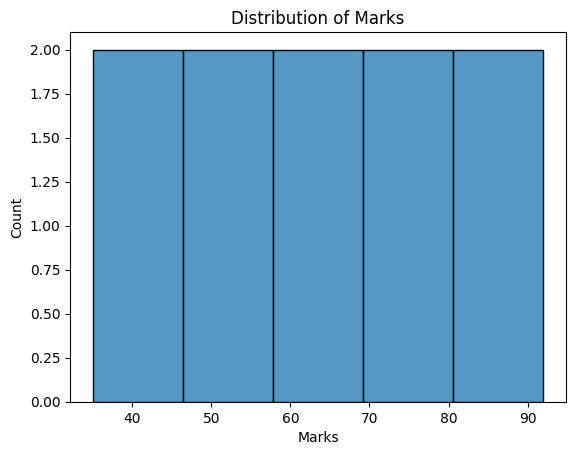

In [37]:
sns.histplot(data=df, x="Marks")
plt.title("Distribution of Marks")
plt.show()

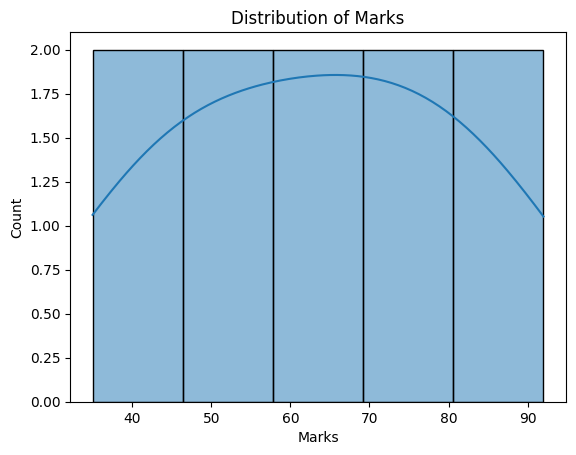

In [38]:
sns.histplot(data=df, x="Marks", kde=True)
plt.title("Distribution of Marks")
plt.show()

In [39]:
data = {
    "Result": [
        "Pass", "Pass", "Fail", "Pass", "Pass",
        "Fail", "Pass", "Fail", "Pass", "Pass"
    ]
}

result_df = pd.DataFrame(data)
print(result_df)

  Result
0   Pass
1   Pass
2   Fail
3   Pass
4   Pass
5   Fail
6   Pass
7   Fail
8   Pass
9   Pass


In [40]:
correlation = df.corr(numeric_only=True)
print(correlation)

             Study_Hours  Attendance     Marks
Study_Hours     1.000000    0.998596  0.999181
Attendance      0.998596    1.000000  0.996911
Marks           0.999181    0.996911  1.000000


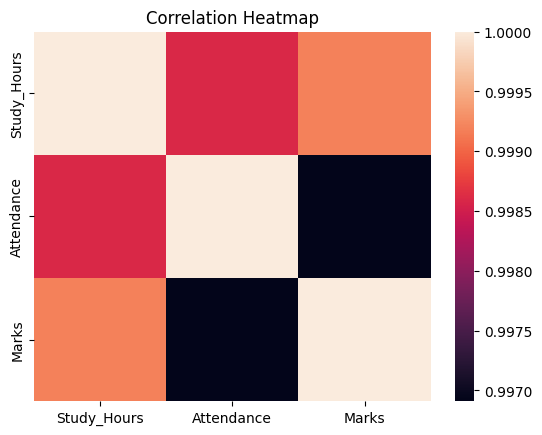

In [41]:
correlation = df.corr(numeric_only=True)

sns.heatmap(correlation)
plt.title("Correlation Heatmap")
plt.show()

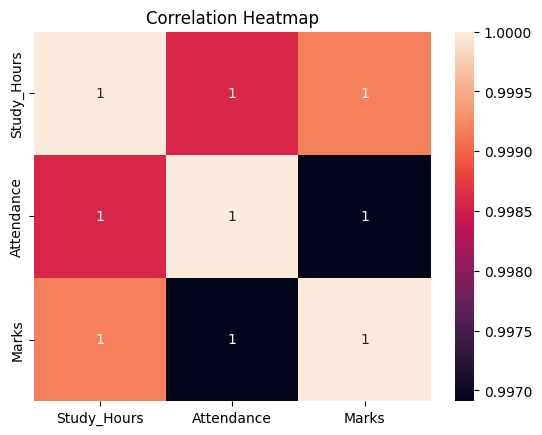

In [42]:
correlation = df.corr(numeric_only=True)

sns.heatmap(correlation, annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [43]:
import sklearn
print(sklearn.__version__)

1.8.0


In [44]:
from sklearn.model_selection import train_test_split
import numpy as np

X = np.array([
    [1], [2], [3], [4], [5],
    [6], [7], [8], [9], [10]
])

y = np.array([
    35, 42, 48, 55, 60,
    68, 72, 78, 85, 92
])

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [46]:
print("X_train:")
print(X_train)

print("y_train:")
print(y_train)

X_train:
[[ 6]
 [ 1]
 [ 8]
 [ 3]
 [10]
 [ 5]
 [ 4]
 [ 7]]
y_train:
[68 35 78 48 92 60 55 72]


In [47]:
print("X_test:")
print(X_test)

print("y_test:")
print(y_test)

X_test:
[[9]
 [2]]
y_test:
[85 42]


In [48]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8, 1)
X_test shape: (2, 1)
y_train shape: (8,)
y_test shape: (2,)
